# Run this chunkk as (1)

✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅

In [ ]:
files = [
    r'..\Data-Working\\BAJAJ-Data.csv', 
    r'..\Data-Working\\HDFCBank-Data.csv', 
    r'..\Data-Working\\Hindalco-Data.csv',
    r'..\Data-Working\\HUL-Data.csv', 
    r'..\Data-Working\\ICICIBank-Data.csv', 
    r'..\Data-Working\\Infosys-Data.csv',
    r'..\Data-Working\\ITC-Data.csv', 
    r'..\Data-Working\\L&T-Data.csv', 
    r'..\Data-Working\\Nifty-50-Data.csv',
    r'..\Data-Working\\Reliance-Data.csv', 
    r'..\Data-Working\\SBI-Data.csv', 
    r'..\Data-Working\\TATAMotors-Data.csv',
    r'..\Data-Working\\TataSteel-Data.csv', 
    r'..\Data-Working\\TCS-Data.csv'
]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

for file in files:
    df = pd.read_csv(file)
    print(f"Processing {file}")
    print(f"Data types:\n {df.dtypes}")


# Do Not run this chunk of code 

❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌❌

In [ ]:
def compute_log_returns_inplace(file_path):
    """
    Reads a CSV, sorts by date, computes log-returns,
    and saves the file back in-place (overwriting).
    """
    print(f"\nProcessing file: {file_path}")
    df = pd.read_csv(file_path)

    # 1. Convert Date and Sort
    # Assuming yyyy-mm-dd format as in the example, otherwise, use dayfirst=True
    # Let's use 'dayfirst=True' to be robust for other formats.
    df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')
    
    # Drop any rows where the date could not be parsed
    df.dropna(subset=['Date'], inplace=True) 
    
    # Sort by date in ascending order
    df.sort_values('Date', inplace=True)

    # 2. Compute Log-Return
    # LOG = log(Price_t / Price_{t-1})
    df['LOG'] = np.log(df['Price'] / df['Price'].shift(1))

    # 3. Handle NaNs
    # The first row will be NaN because there is no Price_{t-1}
    # We drop this row as it's not valid for return calculations
    df.dropna(subset=['LOG'], inplace=True)
    
    if df.empty:
        print("  Warning: No data left after processing. Skipping file.")
        return

    # 4. Save In-Place
    # Overwrite the original file
    df.to_csv(file_path, index=False)
    
    print(f"  ✓ 'LOG' column added and file saved in-place.")
    return

# --- Main Logic ---
folder_path = r"..\Data-Working" 

# Check if the folder exists
if not os.path.isdir(folder_path):
    print(f"Error: Folder not found at {folder_path}")
else:
    # Get all CSVs (assuming you want to process all)
    files_to_process = files

    print(f"Found {len(files_to_process)} files to process in-place...")

    # Loop and process each file
    for file in files_to_process:
        try:
            compute_log_returns_inplace(file)
        except Exception as e:
            print(f"  ✗ FAILED to process {file}: {e}\n")
            continue  # Skip to the next file

    print("\n--- All files processed. ---")

for file in files:
    df = pd.read_csv(file)
    print(f"Processing {file}")
    print(df.shape[0])

# Run this chunk as (2)

✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅✅

# Exploratory Data Analysis (EDA)


In [ ]:
"""
1. Heavy Tails: Financial returns have more extreme values than normal distribution
2. Volatility Clustering: High volatility periods tend to cluster together
3. Leverage Effect: Negative returns often lead to higher future volatility
4. Absence of Return Autocorrelation: Returns are generally not predictable from past returns
5. Correlation Structure: How different assets move together
6. Volatility Regimes: Identifying high-stress periods in markets

Date: Time index
Price: Closing price
Open, High, Low: Price ranges
Vol.: Trading volume
Change %: Percentage change
LOG: Logarithmic returns (already computed)

"""

Found 14 assets. Starting EDA...
1. PRICE SERIES PLOTS


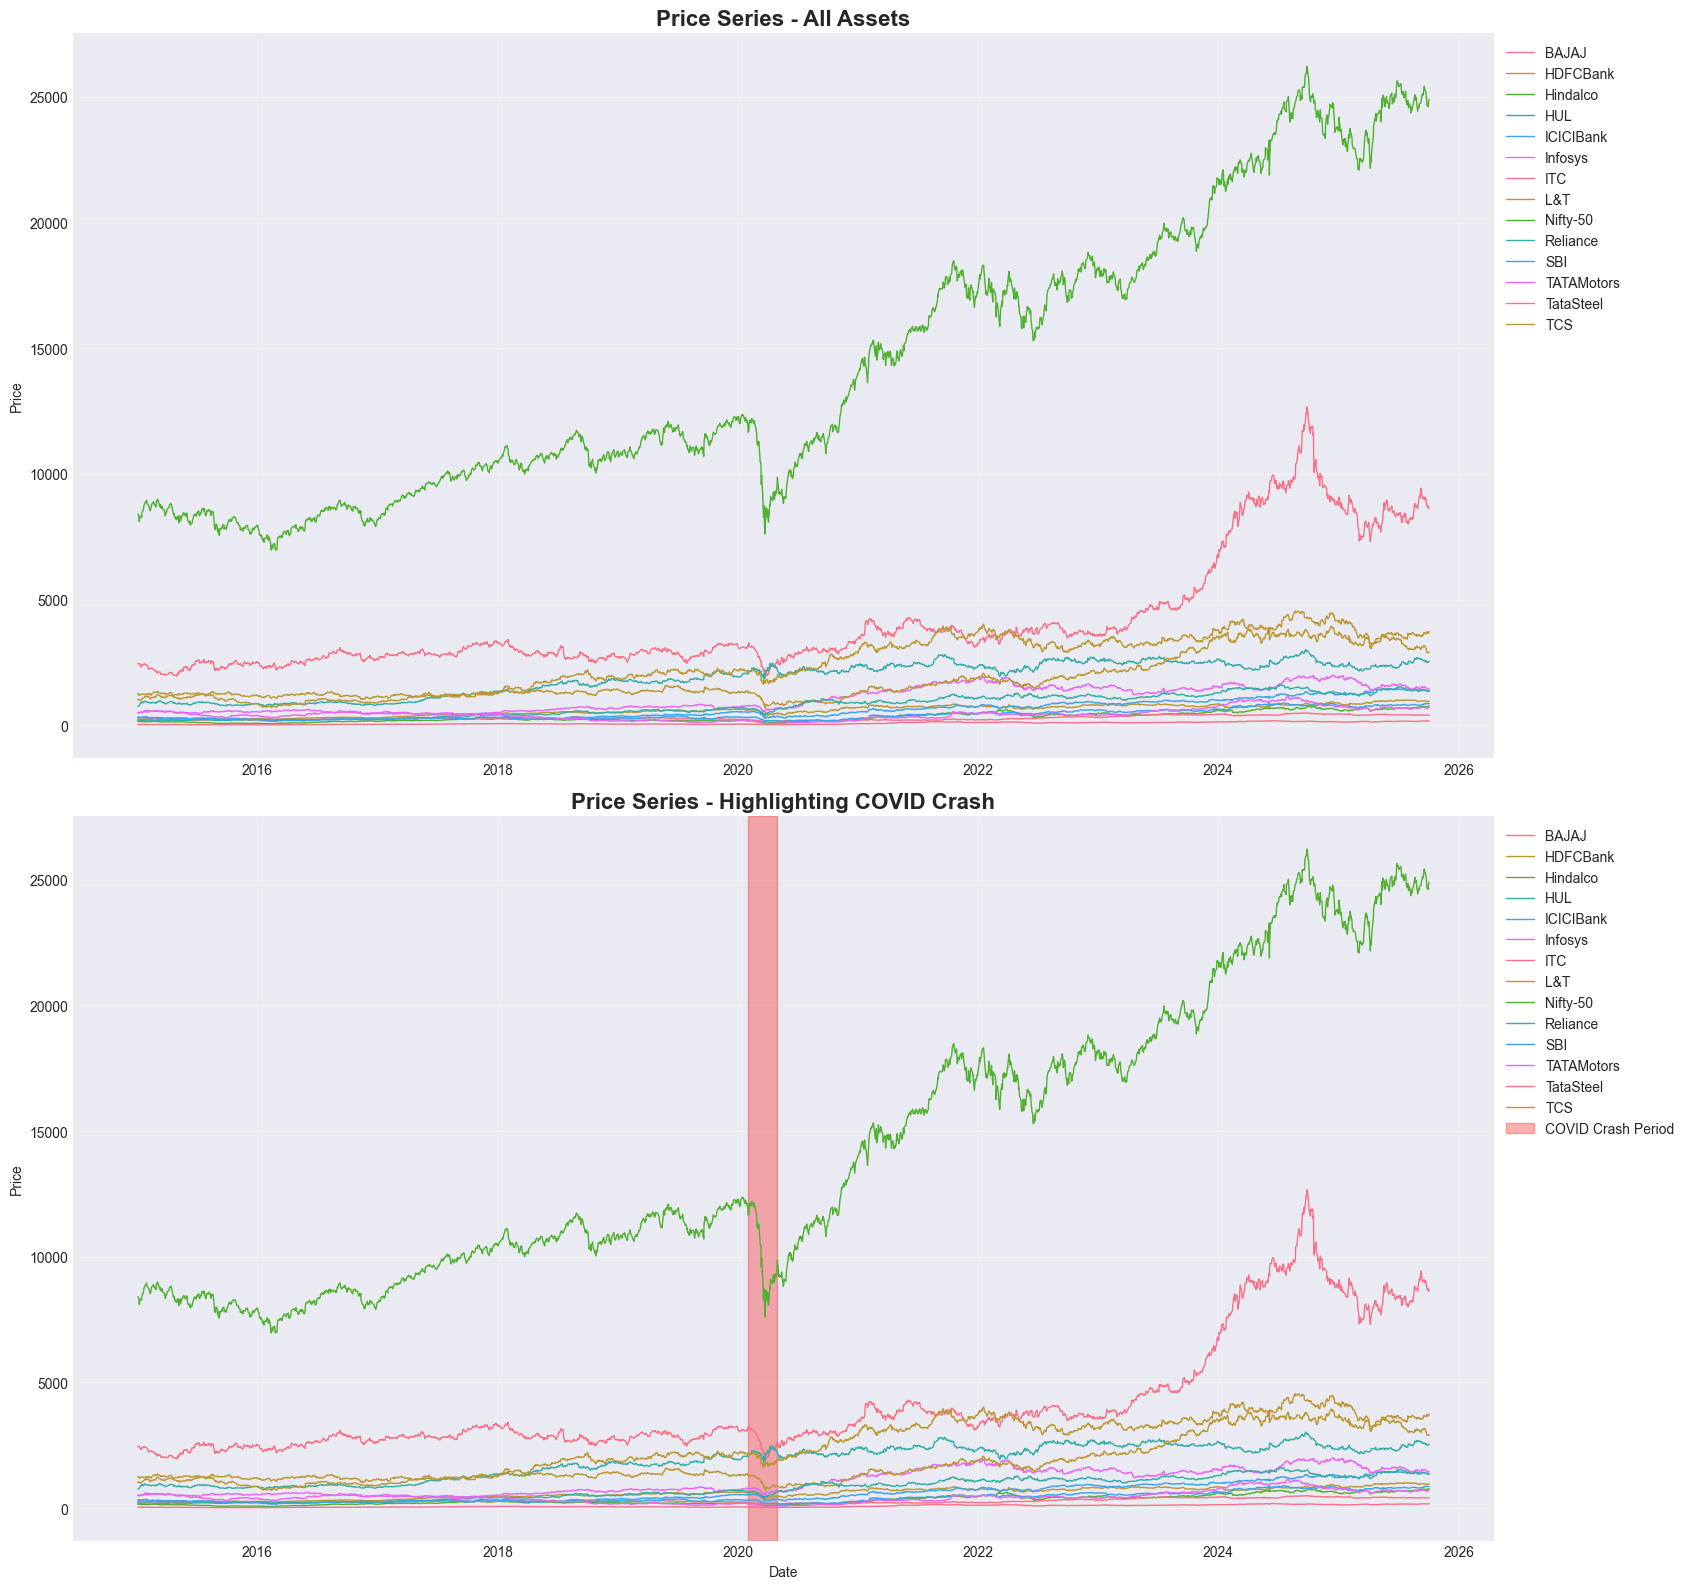


2. RETURN DISTRIBUTION ANALYSIS (Histograms & Q-Q Plots)


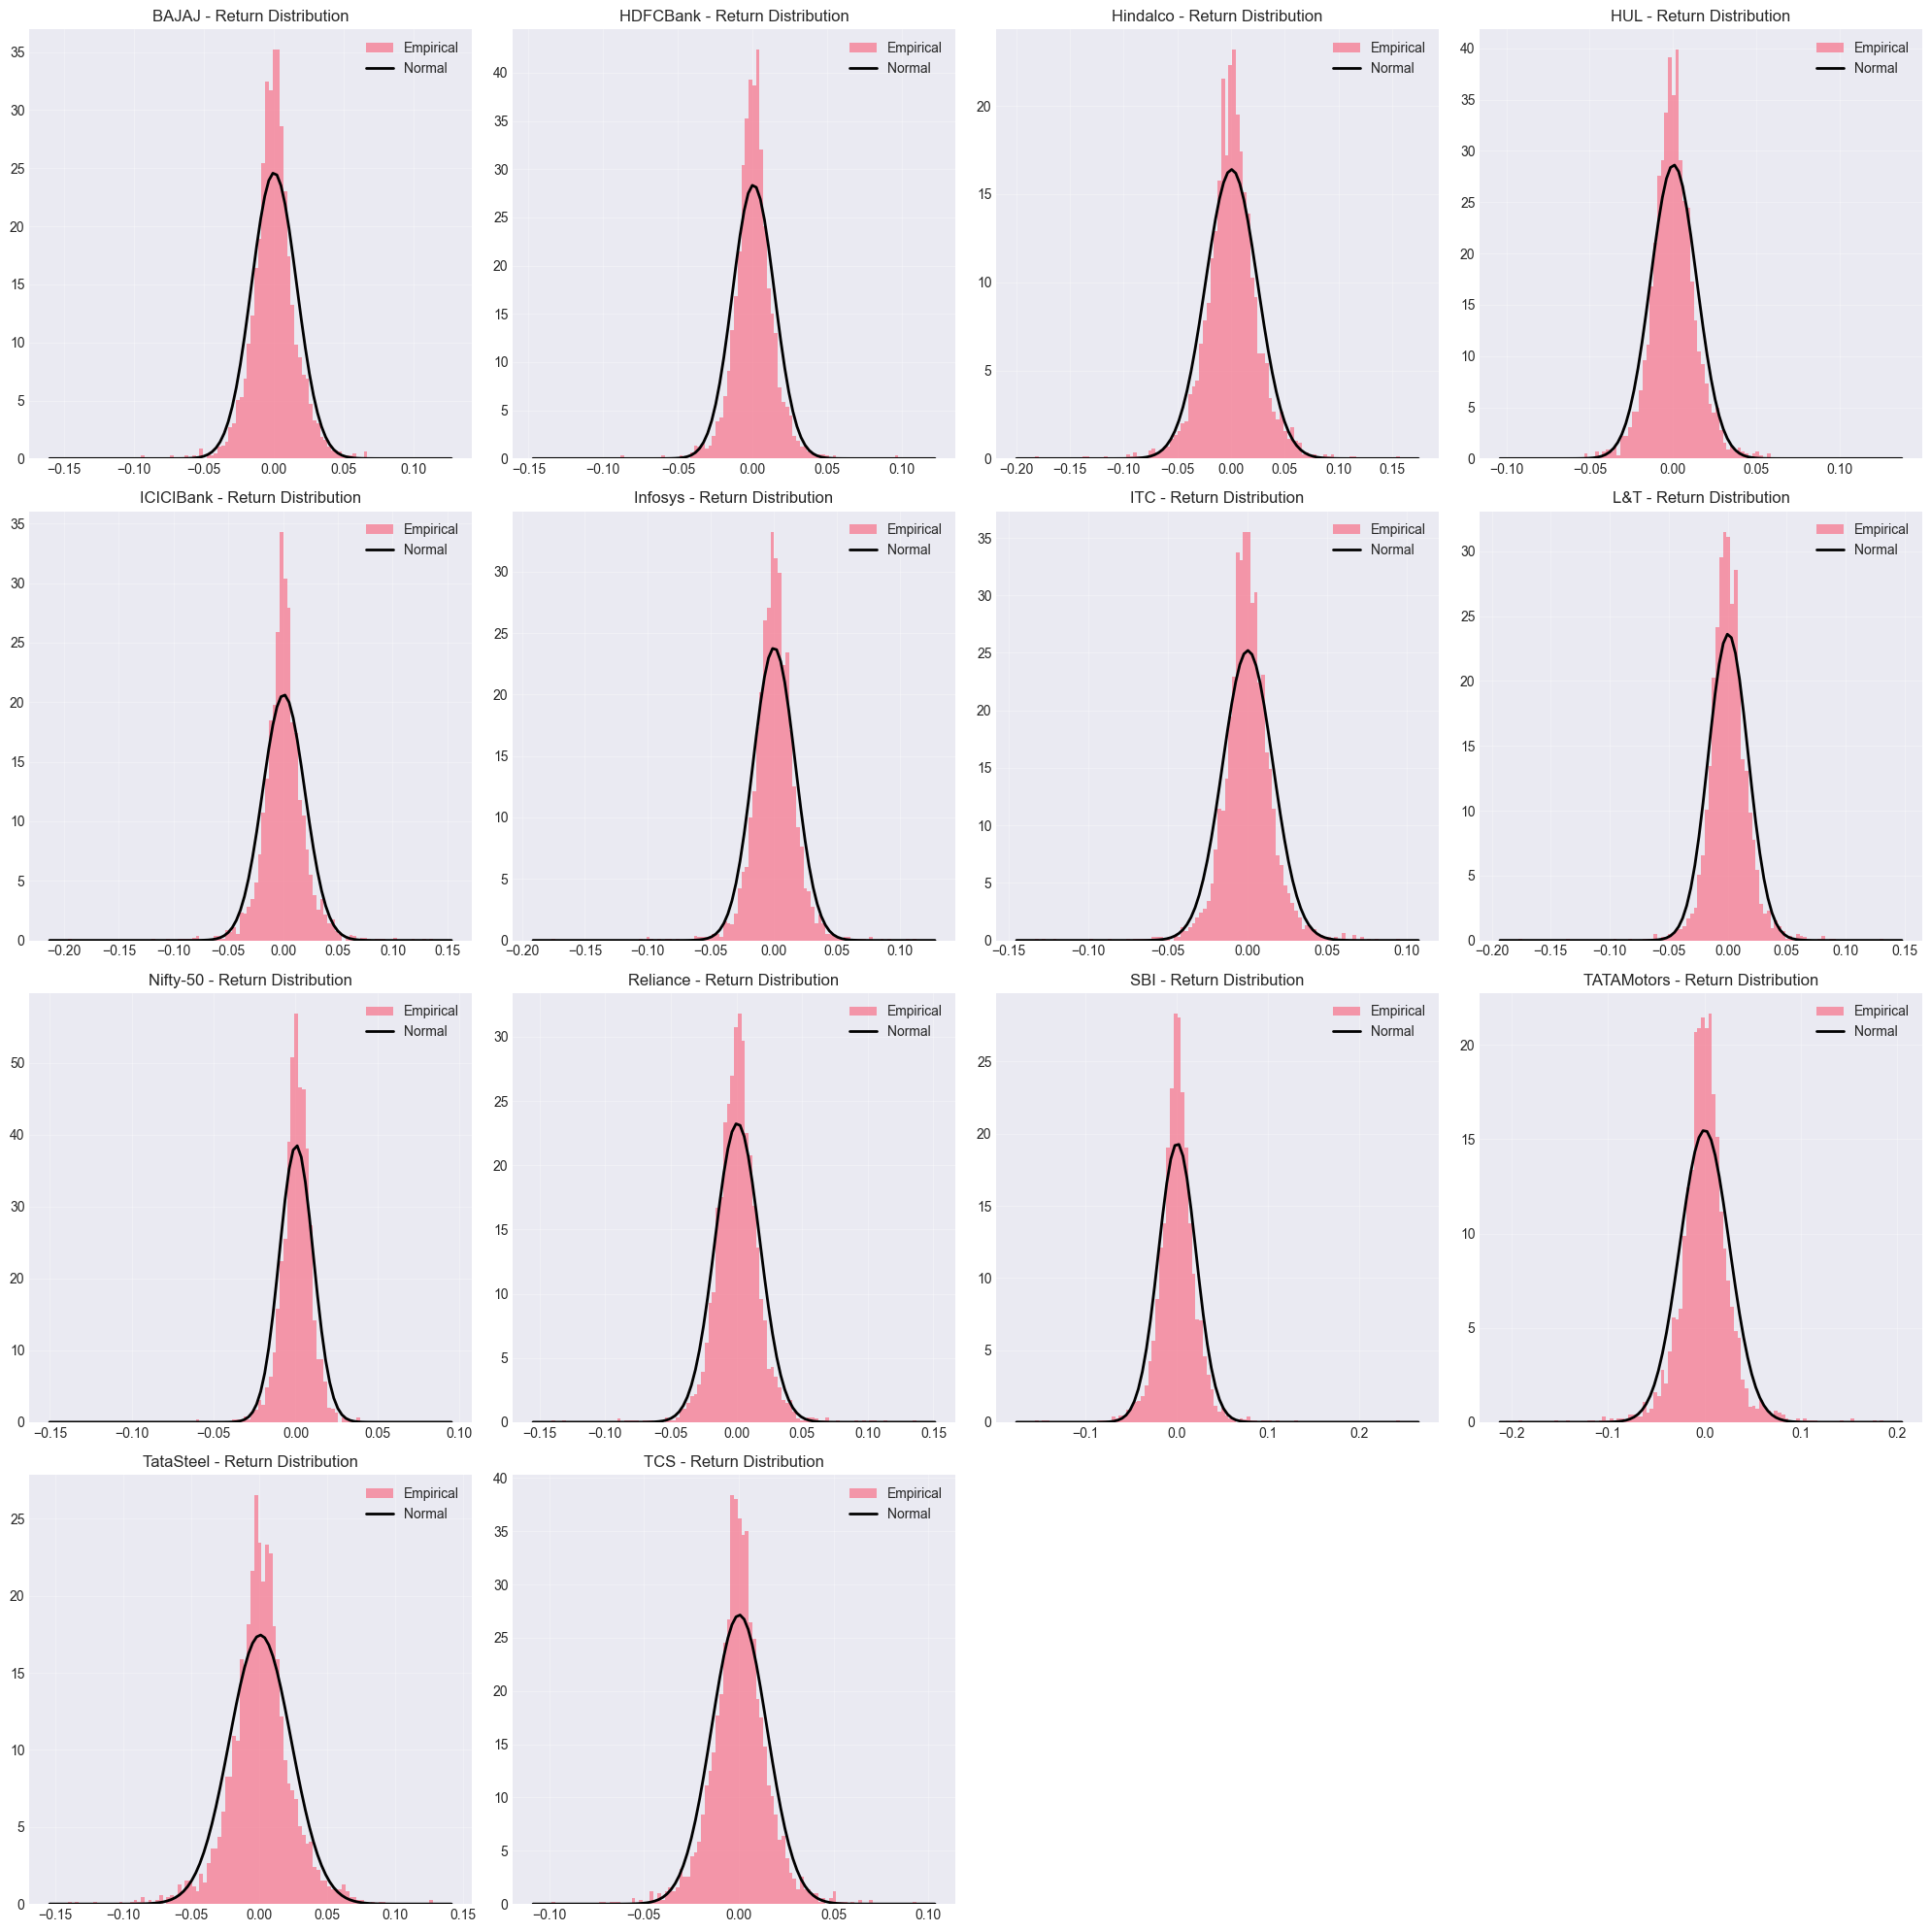

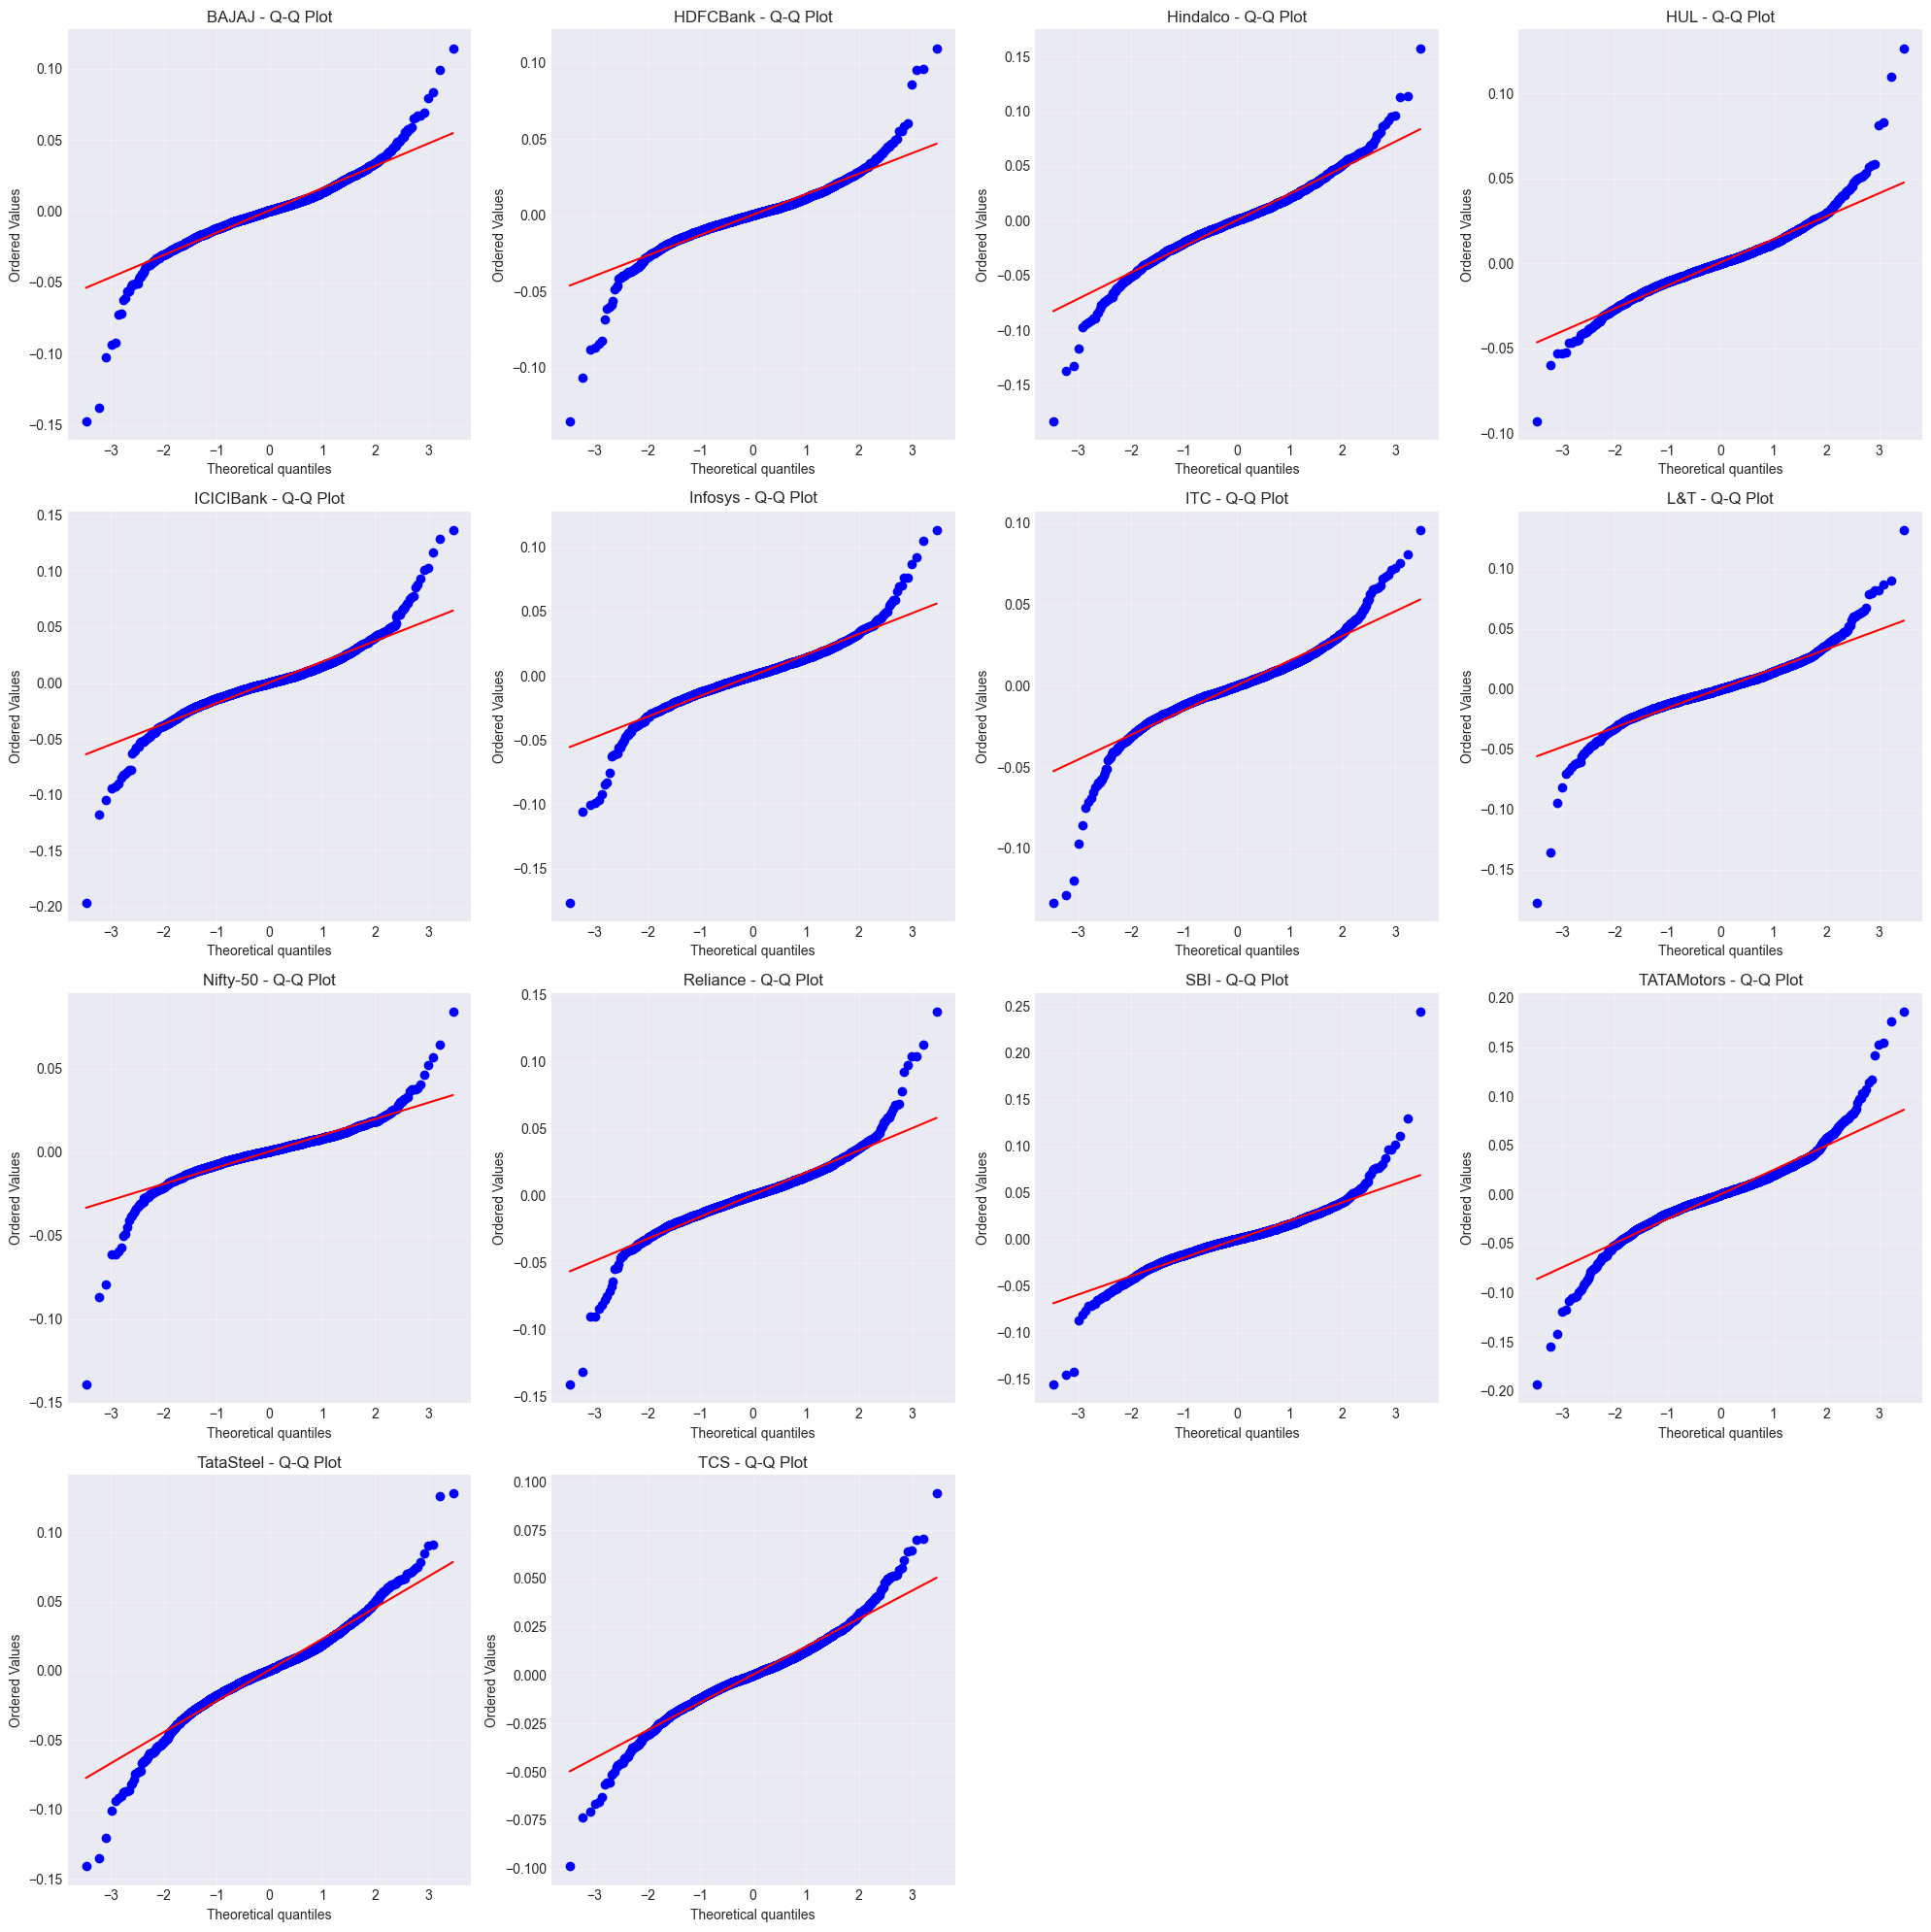


3. STYLIZED FACTS COMPUTATION

--- BAJAJ Stylized Facts ---
  Mean Daily Return: 0.000474
  Std Daily Return: 0.016216
  Skewness: -0.3227
  Excess Kurtosis (Heavy Tails): 8.6292
  Leverage Effect Correlation: 0.0017

--- HDFCBank Stylized Facts ---
  Mean Daily Return: 0.000527
  Std Daily Return: 0.014062
  Skewness: -0.3372
  Excess Kurtosis (Heavy Tails): 10.6792
  Leverage Effect Correlation: 0.0021

--- Hindalco Stylized Facts ---
  Mean Daily Return: 0.000598
  Std Daily Return: 0.024327
  Skewness: -0.2013
  Excess Kurtosis (Heavy Tails): 3.8384
  Leverage Effect Correlation: -0.0099

--- HUL Stylized Facts ---
  Mean Daily Return: 0.000454
  Std Daily Return: 0.013931
  Skewness: 0.6406
  Excess Kurtosis (Heavy Tails): 6.5705
  Leverage Effect Correlation: -0.0049

--- ICICIBank Stylized Facts ---
  Mean Daily Return: 0.000544
  Std Daily Return: 0.019331
  Skewness: -0.1117
  Excess Kurtosis (Heavy Tails): 9.3213
  Leverage Effect Correlation: -0.0100

--- Infosys Stylized F

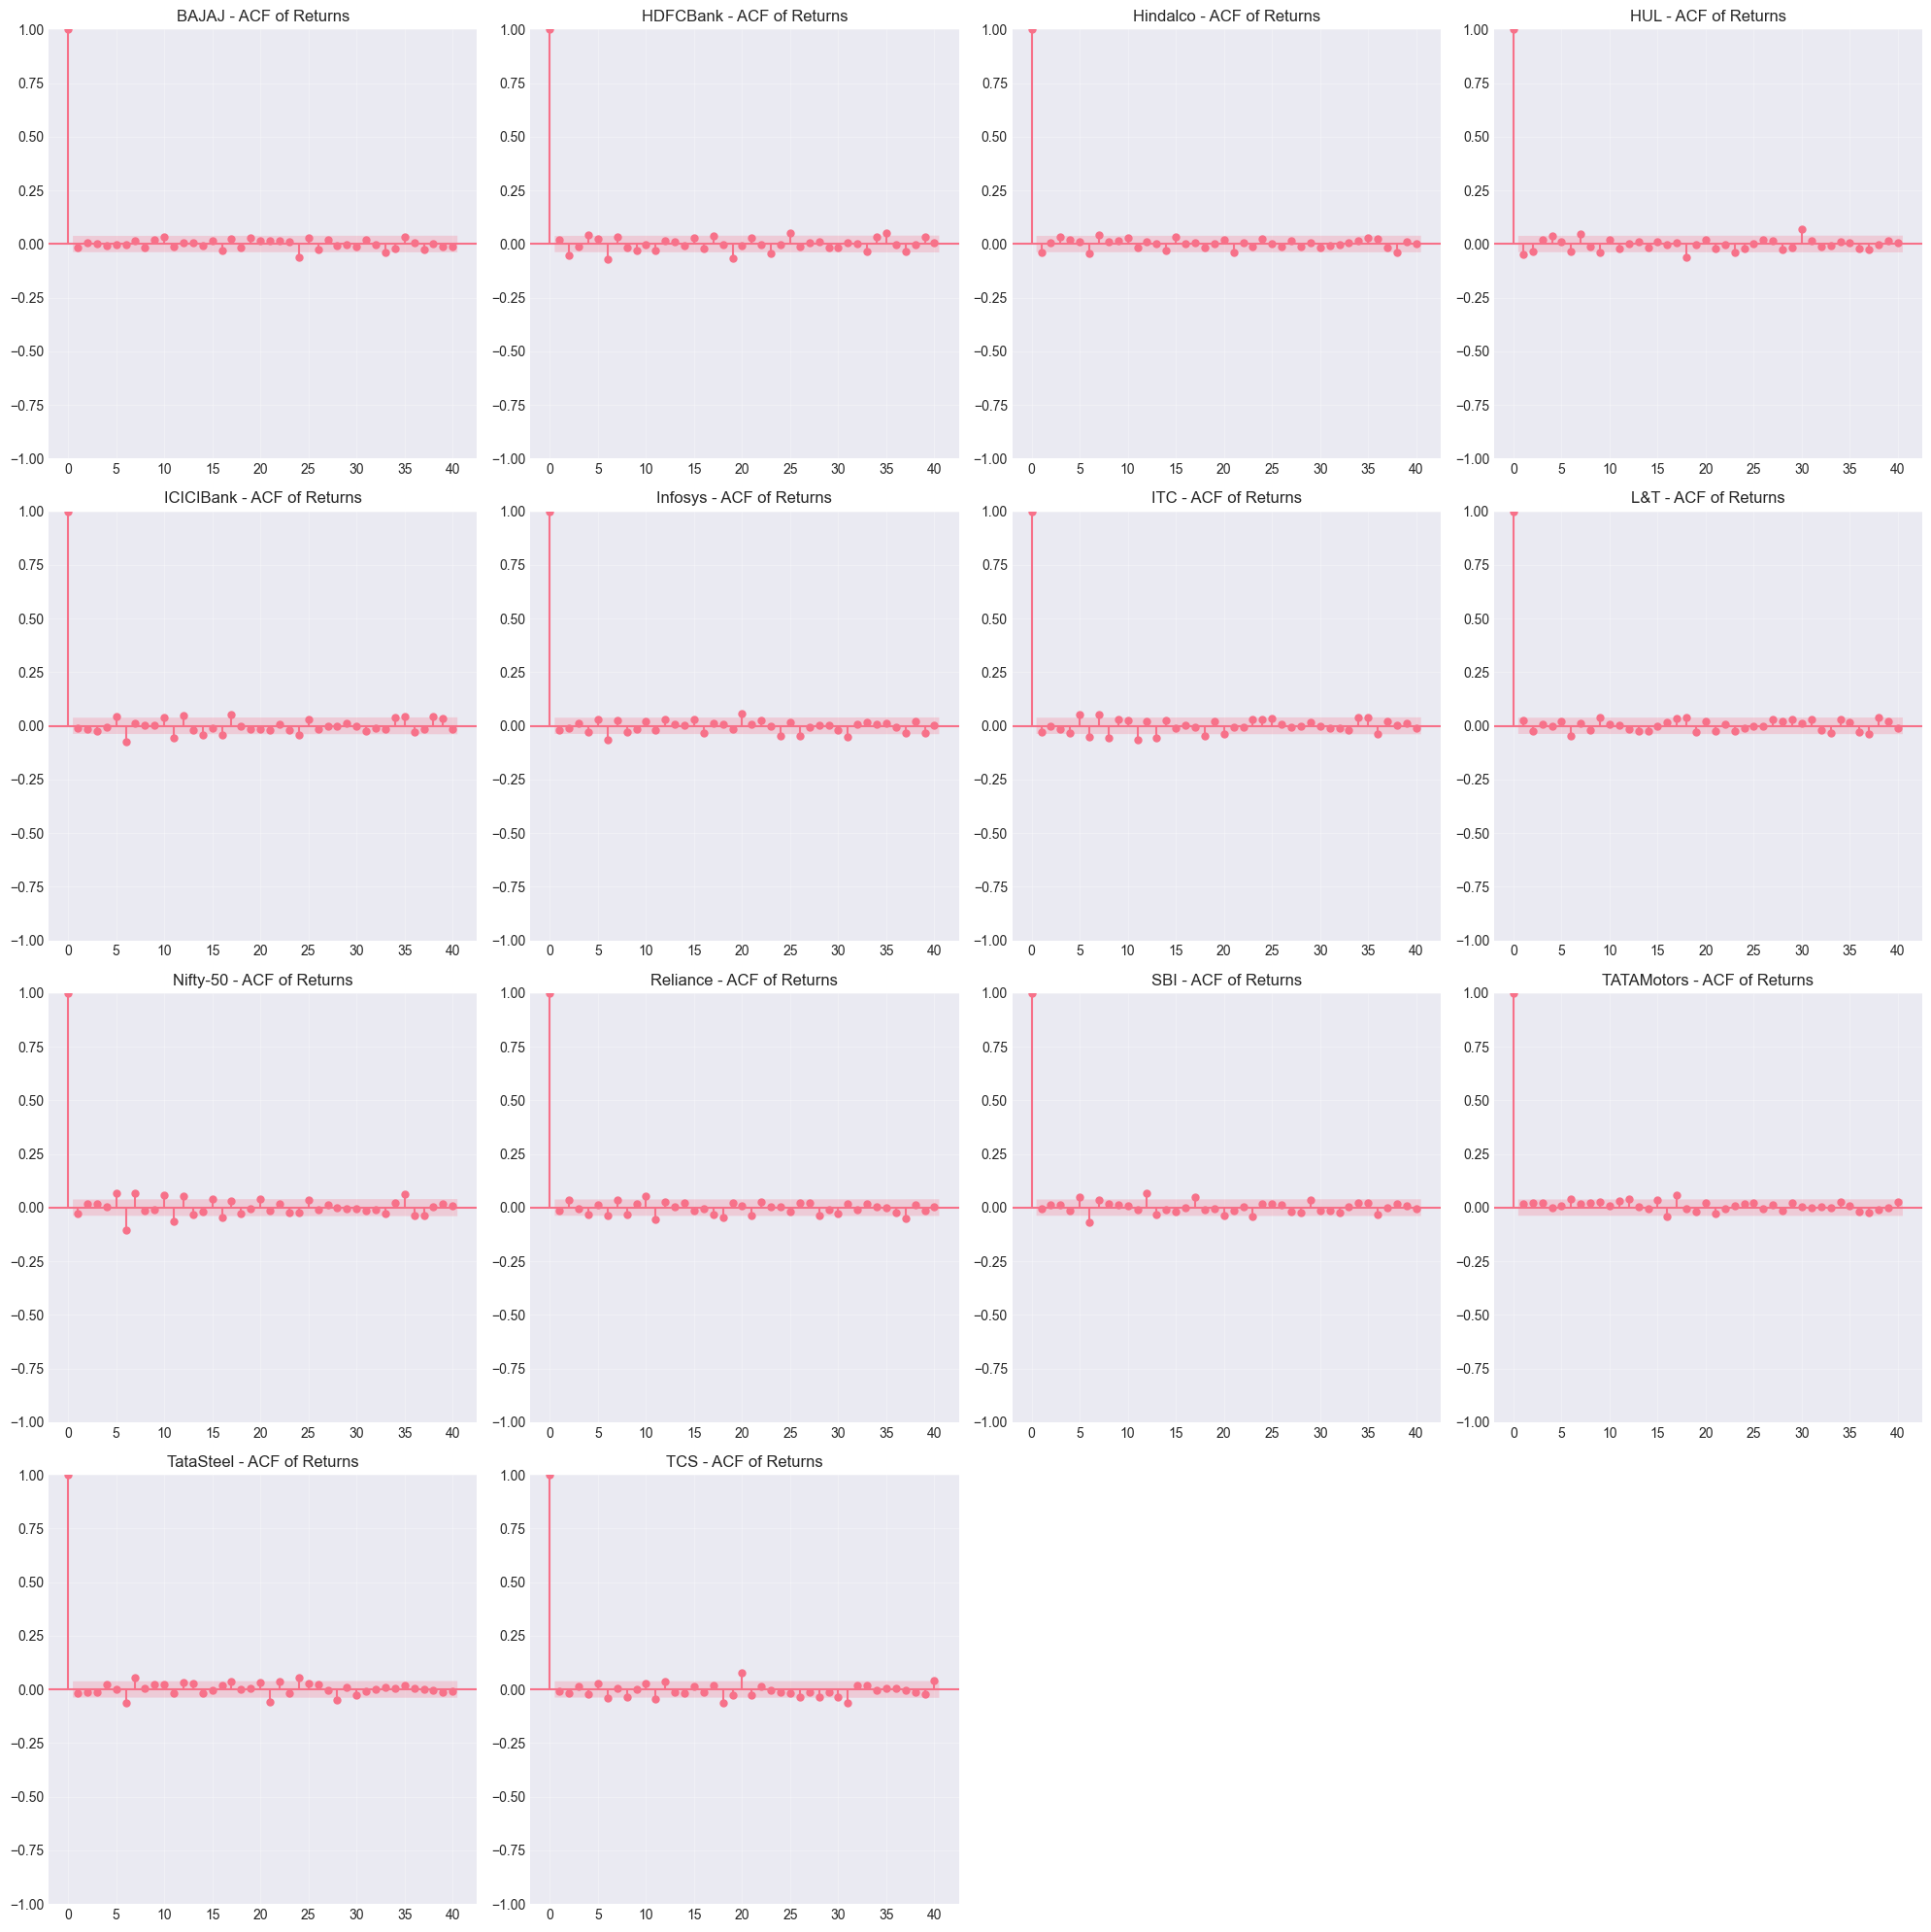

  Plotting ACF of Squared Returns (should show correlation)


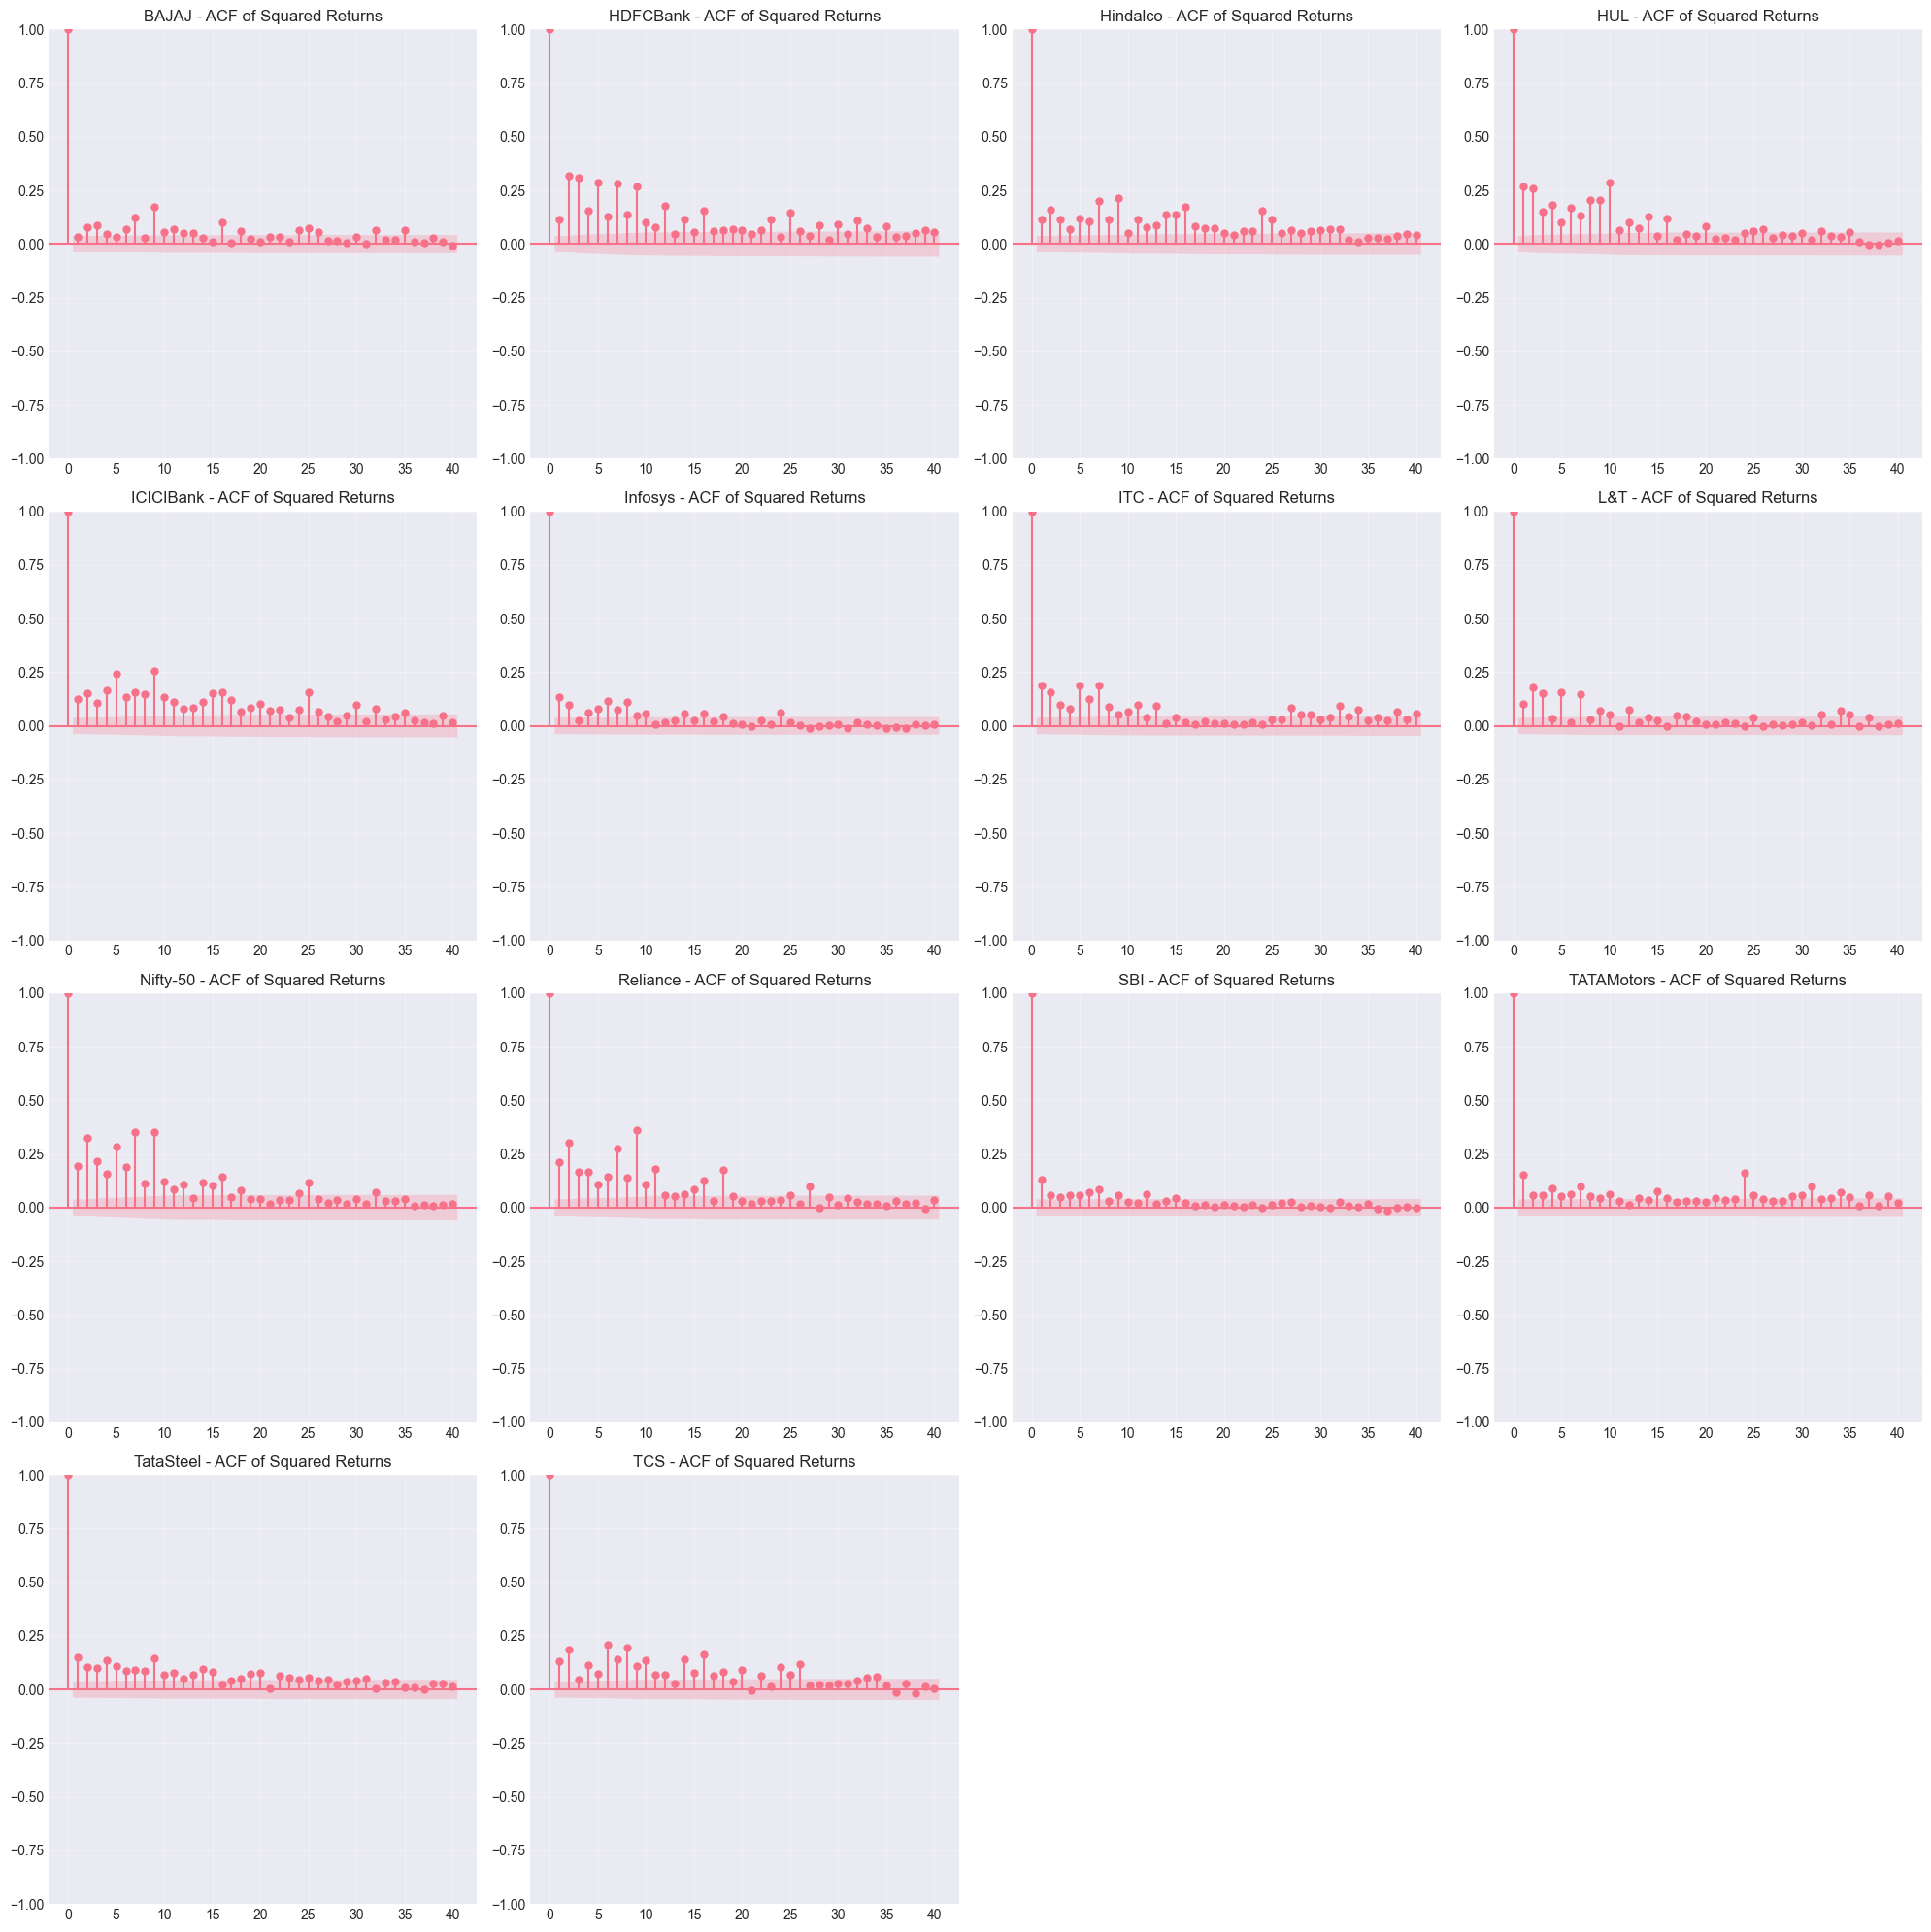


5. CORRELATION MATRIX BETWEEN ASSETS


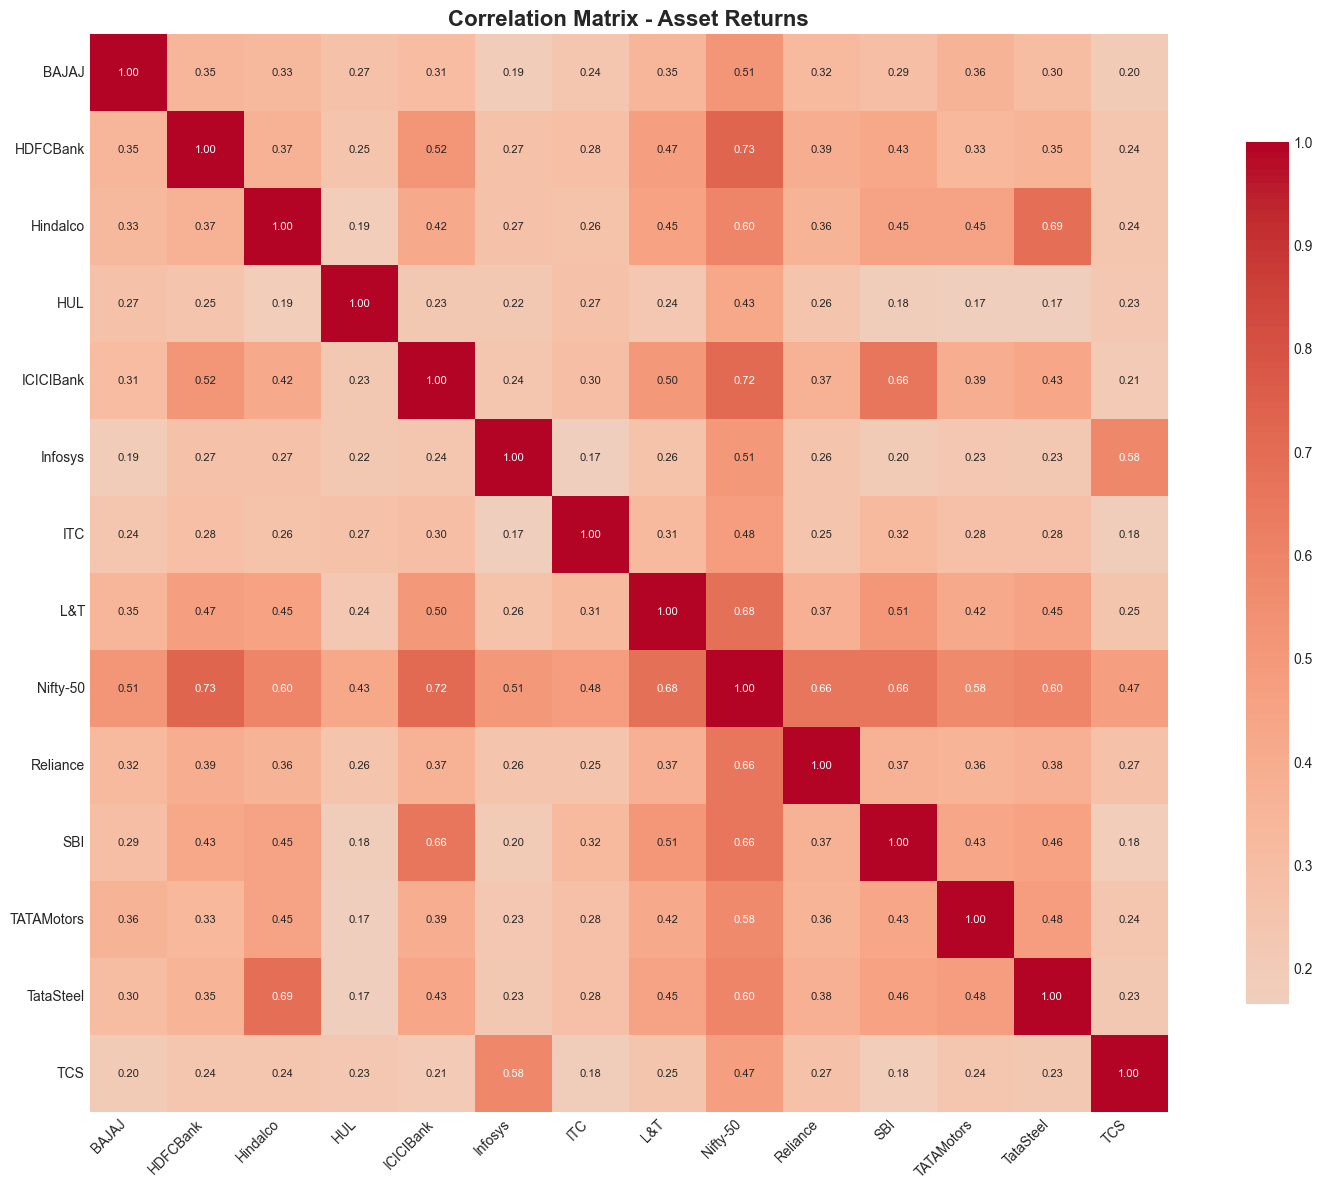

Correlation Matrix:
             BAJAJ  HDFCBank  Hindalco     HUL  ICICIBank  Infosys     ITC  \
BAJAJ       1.0000    0.3479    0.3261  0.2720     0.3104   0.1917  0.2374   
HDFCBank    0.3479    1.0000    0.3706  0.2546     0.5169   0.2689  0.2839   
Hindalco    0.3261    0.3706    1.0000  0.1867     0.4165   0.2673  0.2606   
HUL         0.2720    0.2546    0.1867  1.0000     0.2264   0.2249  0.2699   
ICICIBank   0.3104    0.5169    0.4165  0.2264     1.0000   0.2414  0.2963   
Infosys     0.1917    0.2689    0.2673  0.2249     0.2414   1.0000  0.1695   
ITC         0.2374    0.2839    0.2606  0.2699     0.2963   0.1695  1.0000   
L&T         0.3461    0.4694    0.4530  0.2371     0.5044   0.2603  0.3124   
Nifty-50    0.5147    0.7317    0.6014  0.4289     0.7192   0.5063  0.4842   
Reliance    0.3175    0.3945    0.3640  0.2578     0.3735   0.2569  0.2535   
SBI         0.2903    0.4276    0.4478  0.1811     0.6593   0.2018  0.3201   
TATAMotors  0.3646    0.3317    0.4502  0.17

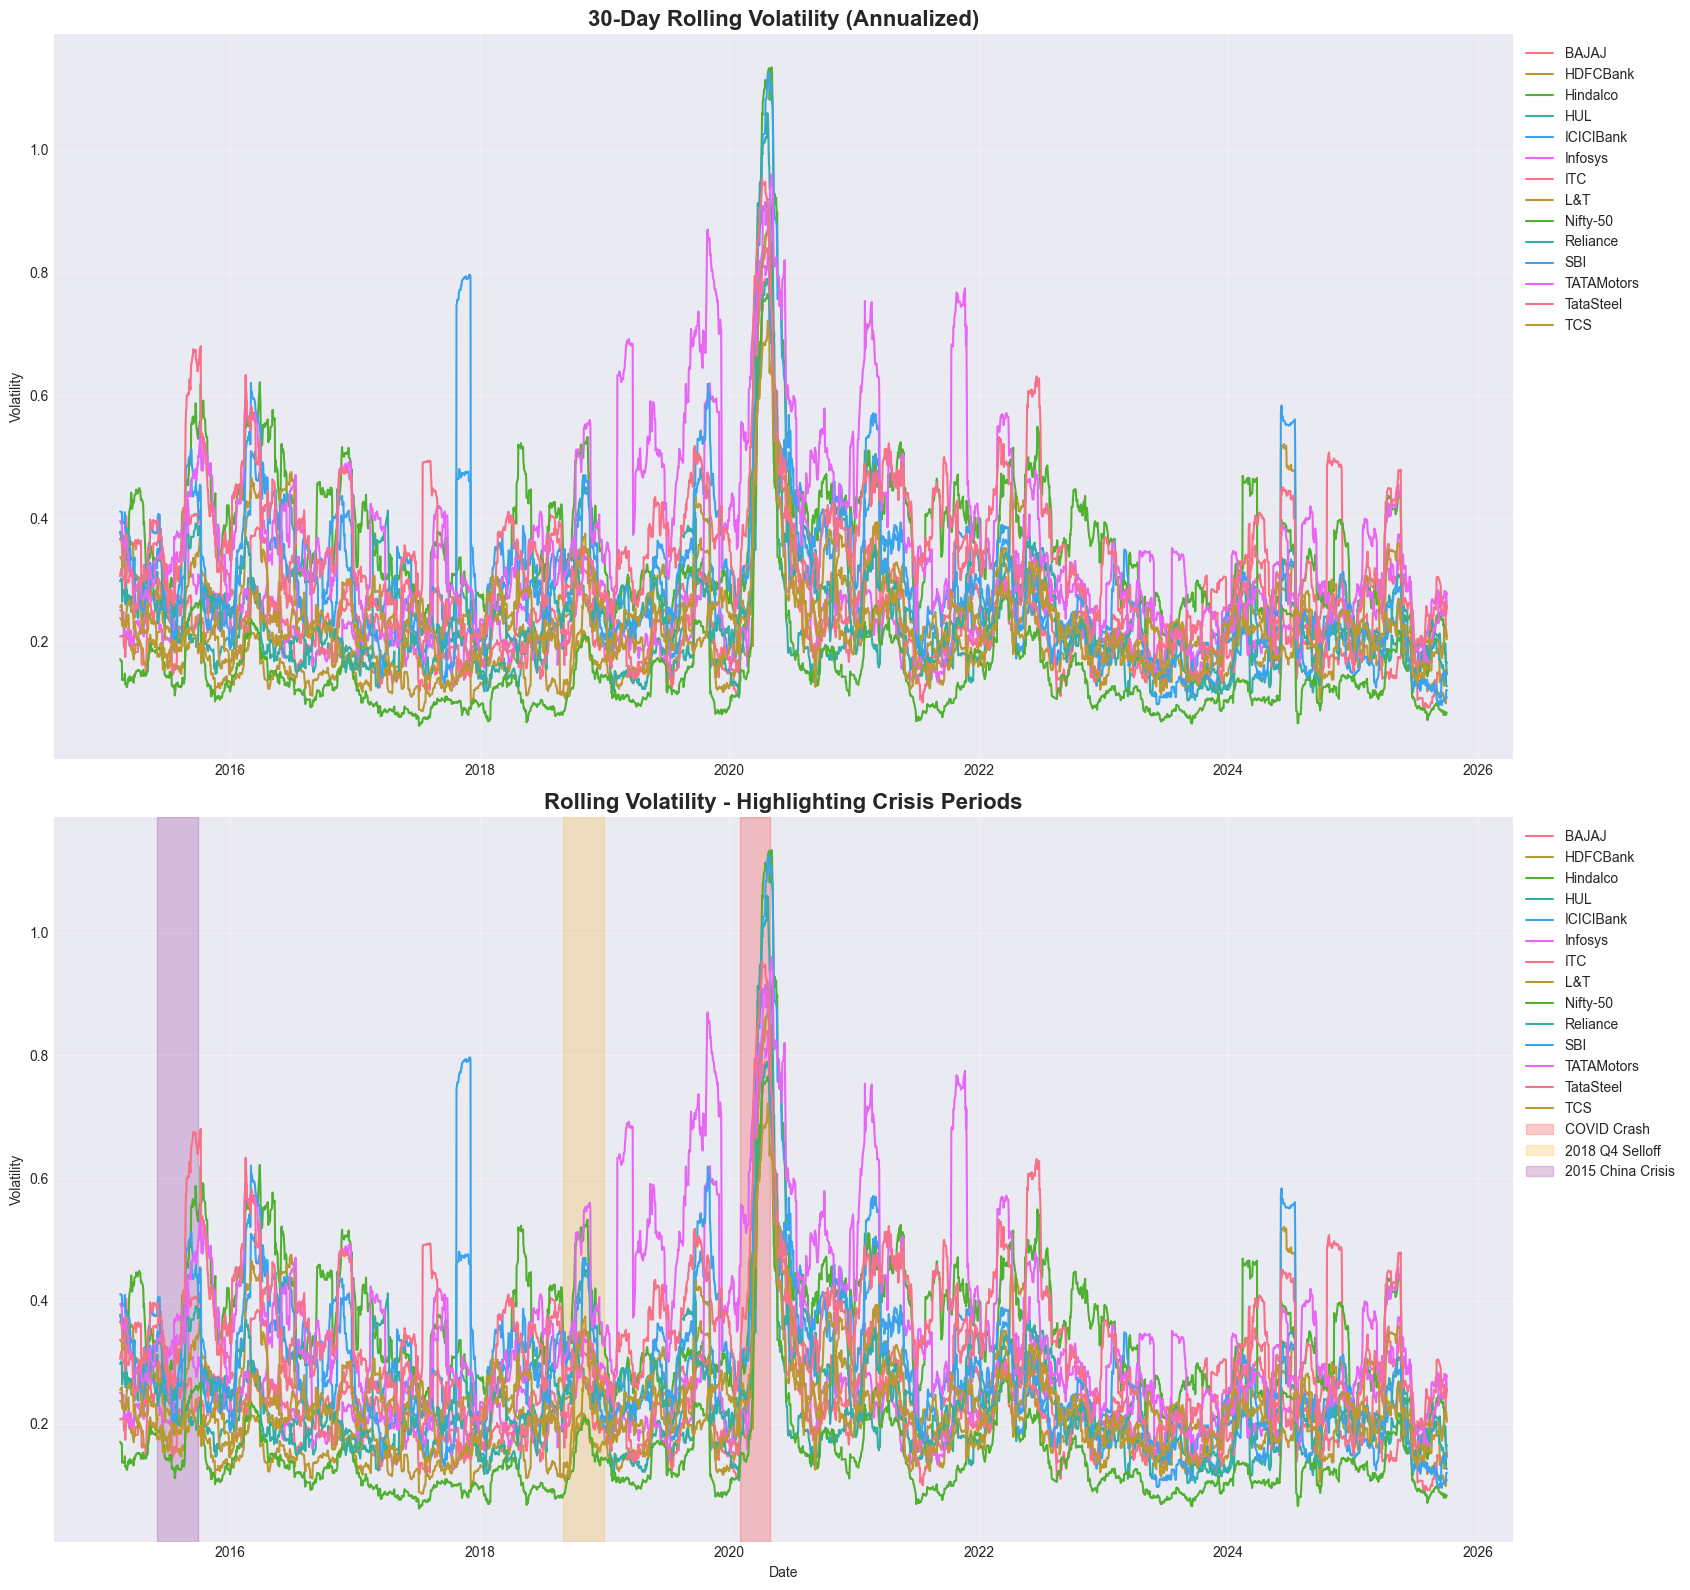


--- EDA Complete ---


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
import os
import warnings

# Suppress common warnings
warnings.filterwarnings('ignore')

# Set style for better plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


def comprehensive_eda(file_paths, asset_names):
    """
    Perform comprehensive exploratory data analysis on financial time series.
    This version is adapted for a larger number of assets (like 14)
    by wrapping subplots for readability.
    """
    
    # --- 1. Read and Prepare Data ---
    data_frames = {}
    returns_data = {}
    
    for i, file_path in enumerate(file_paths):
        df = pd.read_csv(file_path)
        df['Date'] = pd.to_datetime(df['Date'])
        df.set_index('Date', inplace=True)
        data_frames[asset_names[i]] = df
        returns_data[asset_names[i]] = df['LOG']
    
    # Create a combined dataframe for correlation analysis
    combined_returns = pd.DataFrame(returns_data).dropna()
    
    # --- 2. Price Series Plots (All Assets) ---
    print("1. PRICE SERIES PLOTS")
    # With 14 assets, we need a larger plot
    fig, axes = plt.subplots(2, 1, figsize=(20, 16))
    
    for asset in asset_names:
        axes[0].plot(data_frames[asset].index, data_frames[asset]['Price'], 
                     label=asset, linewidth=1)
    axes[0].set_title('Price Series - All Assets', fontsize=16, fontweight='bold')
    axes[0].set_ylabel('Price')
    axes[0].legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    axes[0].grid(True, alpha=0.3)
    
    # Highlight COVID period (March 2020)
    covid_period = pd.date_range('2020-02-01', '2020-04-30')
    for asset in asset_names:
        axes[1].plot(data_frames[asset].index, data_frames[asset]['Price'], 
                     label=asset, linewidth=1)
    axes[1].axvspan(covid_period[0], covid_period[-1], alpha=0.3, color='red', 
                    label='COVID Crash Period')
    axes[1].set_title('Price Series - Highlighting COVID Crash', fontsize=16, fontweight='bold')
    axes[1].set_ylabel('Price')
    axes[1].set_xlabel('Date')
    axes[1].legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout(rect=[0, 0, 0.85, 1]) # Adjust layout to make room for legend
    plt.show()
    
    # --- 3. Return Distribution Analysis (WRAPPED GRID) ---
    print("\n2. RETURN DISTRIBUTION ANALYSIS (Histograms & Q-Q Plots)")
    
    # Define grid layout (4 plots per row)
    ncols = 4
    nrows = int(np.ceil(len(asset_names) / ncols))
    
    # Plot Histograms
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5 * nrows))
    axes = axes.flatten() # Flatten 2D array for easy looping
    
    for i, asset in enumerate(asset_names):
        returns = returns_data[asset]
        
        # Histogram with normal distribution overlay
        axes[i].hist(returns, bins=100, density=True, alpha=0.7, label='Empirical')
        
        # Fit normal distribution
        xmin, xmax = axes[i].get_xlim()
        x = np.linspace(xmin, xmax, 100)
        p = stats.norm.pdf(x, returns.mean(), returns.std())
        axes[i].plot(x, p, 'k', linewidth=2, label='Normal')
        
        axes[i].set_title(f'{asset} - Return Distribution')
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)
        
    # Hide any unused subplots
    for i in range(len(asset_names), len(axes)):
        fig.delaxes(axes[i])
        
    plt.tight_layout()
    plt.show()

    # Plot Q-Q Plots
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5 * nrows))
    axes = axes.flatten()
    
    for i, asset in enumerate(asset_names):
        stats.probplot(returns_data[asset], dist="norm", plot=axes[i])
        axes[i].set_title(f'{asset} - Q-Q Plot')
        axes[i].grid(True, alpha=0.3)

    # Hide any unused subplots
    for i in range(len(asset_names), len(axes)):
        fig.delaxes(axes[i])
        
    plt.tight_layout()
    plt.show()
    
    # --- 4. Stylized Facts Computation ---
    print("\n3. STYLIZED FACTS COMPUTATION")
    stylized_facts = {}
    
    for asset in asset_names:
        returns = returns_data[asset]
        
        # **FIXED**: Use fisher=True to get excess kurtosis directly (Normal=0)
        excess_kurtosis = stats.kurtosis(returns, fisher=True)
        
        # Volatility clustering (ACF of squared returns)
        squared_returns = returns ** 2
        
        # Leverage effect (correlation between returns and future volatility changes)
        future_volatility = squared_returns.shift(-1)
        leverage_corr = returns.corr(future_volatility)
        
        stylized_facts[asset] = {
            'Excess Kurtosis': excess_kurtosis,
            'Leverage Effect Correlation': leverage_corr,
            'Mean Return': returns.mean(),
            'Std Return': returns.std(),
            'Skewness': stats.skew(returns)
        }
        
        print(f"\n--- {asset} Stylized Facts ---")
        print(f"  Mean Daily Return: {returns.mean():.6f}")
        print(f"  Std Daily Return: {returns.std():.6f}")
        print(f"  Skewness: {stats.skew(returns):.4f}")
        print(f"  Excess Kurtosis (Heavy Tails): {excess_kurtosis:.4f}")
        print(f"  Leverage Effect Correlation: {leverage_corr:.4f}")

    # --- 5. Stylized Facts Plots (ACF - WRAPPED GRID) ---
    print("\n4. AUTOCORRELATION PLOTS (Stylized Facts)")
    
    # Plot ACF of Returns (Absence of Autocorrelation)
    print("  Plotting ACF of Returns (should show no correlation)")
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5 * nrows))
    axes = axes.flatten()
    
    for i, asset in enumerate(asset_names):
        # **FIXED**: Use plot_acf to show confidence intervals
        plot_acf(returns_data[asset], ax=axes[i], lags=40, title=f'{asset} - ACF of Returns')
        axes[i].grid(True, alpha=0.3)

    for i in range(len(asset_names), len(axes)):
        fig.delaxes(axes[i])
        
    plt.tight_layout()
    plt.show()

    # Plot ACF of Squared Returns (Volatility Clustering)
    print("  Plotting ACF of Squared Returns (should show correlation)")
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5 * nrows))
    axes = axes.flatten()
    
    for i, asset in enumerate(asset_names):
        # **FIXED**: Use plot_acf to show confidence intervals
        plot_acf(returns_data[asset]**2, ax=axes[i], lags=40, title=f'{asset} - ACF of Squared Returns')
        axes[i].grid(True, alpha=0.3)

    for i in range(len(asset_names), len(axes)):
        fig.delaxes(axes[i])
        
    plt.tight_layout()
    plt.show()
    
    # --- 6. Correlation Matrix Between Assets ---
    print("\n5. CORRELATION MATRIX BETWEEN ASSETS")
    
    plt.figure(figsize=(16, 12))
    correlation_matrix = combined_returns.corr()
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
                square=True, fmt='.2f', cbar_kws={'shrink': 0.8}, annot_kws={"size": 8})
    plt.title('Correlation Matrix - Asset Returns', fontsize=16, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    print("Correlation Matrix:")
    print(correlation_matrix.round(4))
    
    # --- 7. Identify Periods of High Volatility ---
    print("\n6. VOLATILITY ANALYSIS (30-Day Rolling)")
    
    fig, axes = plt.subplots(2, 1, figsize=(20, 16))
    
    for asset in asset_names:
        returns = returns_data[asset]
        rolling_volatility = returns.rolling(window=30).std() * np.sqrt(252) # Annualized
        
        axes[0].plot(returns.index, rolling_volatility, label=asset, linewidth=1.5)
    
    axes[0].set_title('30-Day Rolling Volatility (Annualized)', fontsize=16, fontweight='bold')
    axes[0].set_ylabel('Volatility')
    axes[0].legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    axes[0].grid(True, alpha=0.3)
    
    # Highlight specific crisis periods
    crisis_periods = {
        'COVID Crash': ('2020-02-01', '2020-04-30'),
        '2018 Q4 Selloff': ('2018-09-01', '2018-12-31'),
        '2015 China Crisis': ('2015-06-01', '2015-09-30')
    }
    
    for asset in asset_names:
        returns = returns_data[asset]
        rolling_volatility = returns.rolling(window=30).std() * np.sqrt(252)
        axes[1].plot(returns.index, rolling_volatility, label=asset, linewidth=1.5)
    
    colors = ['red', 'orange', 'purple']
    for (label, (start, end)), color in zip(crisis_periods.items(), colors):
        crisis_range = pd.date_range(start, end)
        axes[1].axvspan(crisis_range[0], crisis_range[-1], alpha=0.2, 
                        color=color, label=label)
    
    axes[1].set_title('Rolling Volatility - Highlighting Crisis Periods', 
                      fontsize=16, fontweight='bold')
    axes[1].set_ylabel('Volatility')
    axes[1].set_xlabel('Date')
    axes[1].legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout(rect=[0, 0, 0.85, 1]) # Adjust layout
    plt.show()
    
    return stylized_facts, correlation_matrix


# --- MAIN EXECUTION ---
if __name__ == "__main__":
    folder_path = r"..\Data-Working"
    
    # Auto-discover file paths and asset names
    file_paths = []
    asset_names = []
    
    if os.path.isdir(folder_path):
        for f in os.listdir(folder_path):
            # Process original files, not copies or return files
            if f.endswith('.csv'):
                file_paths.append(os.path.join(folder_path, f))
                asset_name = os.path.basename(f).split('-Data')[0]
                asset_names.append(asset_name)
        
        if file_paths:
            print(f"Found {len(asset_names)} assets. Starting EDA...")
            stylized_facts, corr_matrix = comprehensive_eda(file_paths, asset_names)
            print("\n--- EDA Complete ---")
        else:
            print(f"No valid CSV files found in {folder_path}")
    else:
        print(f"Error: Folder not found at {folder_path}")